# Use Case 2:

DÉTECTION DES DOSSIERS SUSPECTS OU BLOQUANTS
# Objectif : 
Mettre en place un système intelligent capable d'identifier proactivement les
déclarations qui présentent un risque élevé d'être bloquées par les autorités
douanières, retournées en raison d'informations manquantes ou incorrectes, ou sujettes
à des irrégularités nécessitant une attention particulière.
# Gain : 
Minimiser les retards, les coûts supplémentaires et les litiges en permettant une
intervention précoce sur les dossiers problématiques.

# Connexion à la base de donnee

In [135]:
# Connexion securisee a la base de donnee
import oracledb
import getpass
wallet_dir = "/home/datascience/wallet/"  # Adjust if your wallet is elsewhere
tns_alias = "hvjd9bdxhnf8mhn5_high"  # Replace with the actual alias, e.g., "mydb_high"
un = "admin" 
pwd = "Zet245_000000"

In [136]:
connection = oracledb.connect(
    user=un,
    password=pw,
    dsn=tns_alias,          # Use the TNS alias instead of a local connection string
    config_dir=wallet_dir,  # Directory with tnsnames.ora and sqlnet.ora
    wallet_location=wallet_dir,  # Directory with wallet files
    wallet_password="mypassword1S@"  # Uncomment if your wallet is encrypted
)

# Chargement des donnees en DataFrame

In [137]:
# Conversion en DataFrame pandas
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
with connection.cursor() as cursor:
    sql = "SELECT * FROM GAINDE.GND_IA_ORBUS_INFINITY_EXTRACT"
    df = pd.read_sql(sql, connection)

In [138]:
# affichage entiere de la sortie
pd.set_option('display.max_columns', None)

# Pour voir toutes les lignes
pd.set_option('display.max_rows', None)

# Pour ne pas tronquer les valeurs dans une cellule`
pd.set_option('display.max_colwidth', None)

# Analyse Exploratoire des Données

**1. Pretraitement des donnees**

In [139]:
# fonction de nettoyage prealable des donnees 
def data_cleaning(df):
    # Supprimer les colonnes numériques avec une seule valeur unique
    nunique = df.select_dtypes(include='number').nunique()
    cols_to_drop = nunique[nunique == 1].index.tolist()
    df.drop(columns=cols_to_drop, inplace=True)

    # Convertir les colonnes numériques avec deux valeurs uniques en booléen
    boolean_cols = nunique[nunique == 2].index.tolist()
    df[boolean_cols] = df[boolean_cols].astype('bool')

    # Correction de types spécifiques
    if 'PAYED_FRAIS_BAD' in df.columns:
        df['PAYED_FRAIS_BAD'] = df['PAYED_FRAIS_BAD'].astype('int', errors='ignore')

    # Supprimer les colonnes objets avec trop de modalités
    object_cols = df.select_dtypes(include='object')
    high_card_cols = [col for col in object_cols if df[col].nunique() >= 3674]
    df.drop(columns=high_card_cols, inplace=True)

    # Supprimer une colonne spécifique si elle existe
    if 'DATE_VALIDITE_CONNAISSEMENT' in df.columns:
        df.drop('DATE_VALIDITE_CONNAISSEMENT', axis=1, inplace=True)

    # Conversion de la colonne ART en entier
    if 'ART' in df.columns:
        df['ART'] = df['ART'].astype('int', errors='ignore')

    # Supprimer les colonnes avec moins de deux modalités
    for col in df.columns:
        if df[col].nunique() < 2:
            df.drop(col, axis=1, inplace=True)

    # Convertir les entiers en float
    for col in df.select_dtypes('int').columns:
        df[col] = df[col].astype('float')

    # Reconvertir les booléens en int 
    for col in df.select_dtypes('bool').columns:
        df[col] = df[col].astype('int')
        
    df = df.drop(columns=[col for col in df.columns if df[col].value_counts().max() < 2])

    return df

In [140]:
# Application et affichage a notre dataFrame
df = data_cleaning(df)
df.head()

,ANNEE_DECLARATION,ANNEE_MANIF,AUTRE_INFORMATION,BUREAU_DECLARATION,BUREAU_MANIF,CODE_AGENT,CODE_CONSIGNATAIRE,CODE_MANUTENTIONNAIRE,CODE_OPERATION,CODE_PAYS_DESTINATION,CODE_TRANSPORTEUR,CONSIGNATAIRE,DATE_ARRIVEE,DATE_BAED,DATE_CREATION,DATE_DECLARATION,DATE_EMBARQUEMENT,DATE_ENREGISTRE_DEMANDE,DATE_TRAITEMENT_DEFINITIVE,DATE_BRIGADE,DECLARANT,DELIVRED_DOCUMENT_BON_CONSIGNATAIRE,DELIVRED_DOCUMENT_BON_MANUTENTIONNAIRE,DELIVRED_DOCUMENT_BON_SORTI_DOUANE,DELIVRED_DOCUMENT_TRANSPORTEUR,DELIVRED_DOCUMENT_VISA_PAD,EMAIL_BENEFICIAIRE,END_TIME,ENLEVEMENT_IS_CAR,ENLEVEMENT_IS_CONTAINER,LIBELLE_PAYS_DESTINATION,LIEU_EMBARQUEMENT,MANUTENTIONNAIRE,MODE_CONDITIONNEMENT,NAVIRE,NBRE_CONTENEUR,NINEA_DECLARANT,NOMBRE_ARTICLE,NOMBRE_COLIS,NUMERO_MANIF,NUMERO_REPERTOIRE,ORDRE,PAVILLON,PAYS_DESTINATION,POIDS,PPM_DECLARANT,PPM_DEMANDEUR,PPM_TRANSITAIRE,PROVENANCE,REGIME_DOUANIER,REGIME_FISCALE,RENVOI_MODIFICATION_CONSIGNATAIRE,SEND_DEMANDE_TO_BRIGADE_COMMERCIALE,SEND_DEMANDE_TO_EMASE,SEND_DEMANDE_TO_GET_PASS,SEND_DEMANDE_TO_TRANSPORTEUR,SENDED_DEMANDE_TO_CONSIGNATAIRE,SENDED_DEMANDE_TO_MANUTENTIONNAIRE,SENDED_DEMANDE_TOPAD,START_TIME,STATUS,STATUSASP,STATUSBADC,STATUSBADM,STATUSBADT,STATUSPAD,STATUT_BAED,STATUT_BRIGAGE_COMMERCIALE,STATUT_GET_PASS,TRANSPORTEUR,TYPEBL,TYPE_ENELEVEMENT,VALAPPROX,VILLE_DESTINATION,DELIVRED_DOCUMENT_BON_EMASE,ZONE_LIVRAISON,ART,DOSSIER_IS_TRANSFERT_TO_OTHER_TRANSITAIRE,DOSSIER_IS_SEND_TO_MANUTENTIONNAIRE,SEND_DEMANDE_TO_FACTURATION,LOCAL_DATEBAD,ENLEVEMENT_IS_VRAC,QUITUS_FRAIS_GUICHET_UNIQUE,MOTIFDOUANE,DESCRIPTION,DEMANDE_IS_SEND_TO_DAKAR_TERMINAL_FORMBAD,DEMANDE_IS_SEND_TO_DAKAR_TERMINAL_FORMBAE,CODE_DOSSIER,DELIVRED_DOCUMENT_COSEC,DOSSIER_IS_REGULE,DATE_SENDED_TO_CONSIGNATAIRE,PAYED_FRAIS_BAD
0,NaN,2024.0,None,None,10S,None,2,MT006,IMPORT001,0005SN,undefined,AFRICA GLOBAL LOGISTICS SENEGAL SA,2024-10-27 00:00:00,NaT,2024-10-29,None,2024-10-20 00:00:00,2024-10-29 10:21:34.374,NaT,NaT,None,1,1,0,1,0,steexpress@live.fr,2024-11-02 23:00:00,0,1,SÉNÉGAL,VALENCE,DP World,CARTON,PEPI STAR,2.0,None,107.0,4272.0,5600,AG2160,None,LIBÉRIA,SÉNÉGAL,36186.0,531174,531174,531174,ESPAGNE,None,None,false,0,0,0,1,1,0,0,2024-11-01 23:00:00,En cours,Initialisée,Délivré,Délivré,Délivré,Initialisée,0,0,1,Facture de transport,B/L Orignal,Conteneur,0.0,DAKAR,0,Dakar,72,0,0,0,2024-11-15,0,1,None,None,0,0,D_NORM,1,0,NaT,1.0
1,2024.0,2024.0,None,15T,10S,None,2,MT006,TRANSIT001,0001ML,undefined,AFRICA GLOBAL LOGISTICS SENEGAL SA,2024-10-27 00:00:00,2024-10-25 15:39:16,2024-10-29,2024-10-25 00:00:00,2024-10-20 00:00:00,2024-10-29 09:57:43.515,NaT,NaT,"TRANSIT KEUR AYIB - SUARL 90-94, RUE ABDOU KARIM BOURGI IMMEUBLE SERIGNE IB DAKAR",1,1,0,1,0,lamaniang96@gmail.com,2024-11-02 23:00:00,0,1,MALI,VALENCE,DP World,COLIS (PARCEL),PEPI STAR,3.0,7261944,107.0,645.0,5600,AG2160,None,LIBÉRIA,MALI,46145.0,141009,141009,141009,ESPAGNE,S1,10,false,0,0,0,1,1,0,0,2024-11-01 23:00:00,En cours,Initialisée,Délivré,Délivré,Délivré,Initialisée,1,0,1,Facture de transport,B/L Orignal,Conteneur,0.0,BAMAKO,0,MOUSSALA,84,0,0,0,2024-11-15,0,1,None,None,0,0,D_NORM,0,0,NaT,1.0
2,2024.0,2024.0,None,18N,18N,None,5265,MT006,IMPORT001,0005SN,undefined,DIAMOND SHIPPING,2024-08-12 00:00:00,2024-08-19 11:29:41,2024-08-13,2024-08-13 00:00:00,2024-08-12 00:00:00,2024-08-13 13:33:23.099,NaT,NaT,"INTERNATIONAL SARL VTRANS RUE DAKAR,44 RUE TOLBIAC 3E ETAGE DAKAR",1,1,0,1,0,baylaythiombane1@gmail.com,2024-08-21 14:00:00,0,1,SÉNÉGAL,YARIMCA,DP World,COLIS (PACKAGE),ULANGA,2.0,4099744,274.0,50.0,5277,102-HL,None,PORTUGAL,SÉNÉGAL,41860.0,85963,85963,85963,MAROC,C1,0,false,0,0,0,1,1,0,0,2024-08-20 14:00:00,En cours,Initialisée,Délivré,Délivré,Délivré,Initialisée,1,0,1,Facture de transport,B/L Orignal,Conteneur,0.0,SNDKR,0,DAKAR,314,0,0,0,2024-08-14,0,1,None,"MATERIAUX DE POSTE,\rPREFABRIQUE SANS BETON",0,0,D_NORM,1,0,NaT,1.0
3,2024.0,2024.0,None,18N,18N,None,5265,MT006,IMPORT001,0005SN,undefined,DIAMOND SHIPPING,2024-09-02 00:00:00,2024-09-06 17:03:08,2024-09-05,2024-09-05 00:00:00,2024-

**2. Description du problème et identification des algorithmes possibles**
Nous cherchons à determiner la probablite qu'un dossier soit regulier.
Les données étant labellisées nous pouvons utiliser les algorithmes d'apprentissage supervisés suivant et les calibrer si besoin: 
- Régression Logistique
- SVM
- Random Forest
- XGBoost
- Lightgbm

## Analyse de forme

- **Variable cible** : DOSSIER_IS_REGULE
- **Forme du dataset** : (69928, 33)
- **Types de variables** : 80 variables categorielles, 39 variables quantitatifs et 17 variables temporelles 
- **Valeurs manquantes** : 18 %

In [141]:
# recssencement des differentes types de donnees
df.dtypes.unique()

array([dtype('float64'), dtype('O'), dtype('<M8[ns]'), dtype('int64')],
      dtype=object)

In [142]:
df.dtypes.value_counts()

object            48
int64             27
datetime64[ns]     9
float64            8
Name: count, dtype: int64

In [143]:
# dimension
df.shape

(110260, 92)

In [144]:
# valeurs manquantes
df.isna().mean().mean()

0.12222809328149277

## Separation des differentes types de variables 

## Variables numeriques

In [145]:
# analyse des variables numeriques
df_num = df.select_dtypes(include=['number'])
df_num['DOSSIER_IS_REGULE'] = df_num['DOSSIER_IS_REGULE'].apply(lambda x: 0 if x == 1 else 1)
df_num.head()

,ANNEE_DECLARATION,ANNEE_MANIF,DELIVRED_DOCUMENT_BON_CONSIGNATAIRE,DELIVRED_DOCUMENT_BON_MANUTENTIONNAIRE,DELIVRED_DOCUMENT_BON_SORTI_DOUANE,DELIVRED_DOCUMENT_TRANSPORTEUR,DELIVRED_DOCUMENT_VISA_PAD,ENLEVEMENT_IS_CAR,ENLEVEMENT_IS_CONTAINER,NBRE_CONTENEUR,NOMBRE_ARTICLE,NOMBRE_COLIS,POIDS,SEND_DEMANDE_TO_BRIGADE_COMMERCIALE,SEND_DEMANDE_TO_EMASE,SEND_DEMANDE_TO_GET_PASS,SEND_DEMANDE_TO_TRANSPORTEUR,SENDED_DEMANDE_TO_CONSIGNATAIRE,SENDED_DEMANDE_TO_MANUTENTIONNAIRE,SENDED_DEMANDE_TOPAD,STATUT_BAED,STATUT_BRIGAGE_COMMERCIALE,STATUT_GET_PASS,VALAPPROX,DELIVRED_DOCUMENT_BON_EMASE,DOSSIER_IS_TRANSFERT_TO_OTHER_TRANSITAIRE,DOSSIER_IS_SEND_TO_MANUTENTIONNAIRE,SEND_DEMANDE_TO_FACTURATION,ENLEVEMENT_IS_VRAC,QUITUS_FRAIS_GUICHET_UNIQUE,DEMANDE_IS_SEND_TO_DAKAR_TERMINAL_FORMBAD,DEMANDE_IS_SEND_TO_DAKAR_TERMINAL_FORMBAE,DELIVRED_DOCUMENT_COSEC,DOSSIER_IS_REGULE,PAYED_FRAIS_BAD
0,NaN,2024.0,1,1,0,1,0,0,1,2.0,107.0,4272.0,36186.0,0,0,0,1,1,0,0,0,0,1,0.0,0,0,0,0,0,1,0,0,1,1,1.0
1,2024.0,2024.0,1,1,0,1,0,0,1,3.0,107.0,645.0,46145.0,0,0,0,1,1,0,0,1,0,1,0.0,0,0,0,0,0,1,0,0,0,1,1.0
2,2024.0,2024.0,1,1,0,1,0,0,1,2.0,274.0,50.0,41860.0,0,0,0,1,1,0,0,1,0,1,0.0,0,0,0,0,0,1,0,0,1,1,1.0
3,2024.0,2024.0,1,1,0,1,0,0,1,4.0,109.0,13776.0,89480.0,0,0,0,1,1,0,0,1,0,1,0.0,0,0,0,0,0,1,0,0,1,1,1.0
4,2024.0,2024.0,1,1,0,1,0,0,1,1.0,396.0,895.0,25648.0,0,0,0,1,1,0,0,1,0,0,0.0,0,0,0,0,0,1,1,1,1,1,1.0


### Analyse de fond

In [146]:
# info
df_num.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110260 entries, 0 to 110259
Data columns (total 35 columns):
 #   Column                                     Non-Null Count   Dtype  
---  ------                                     --------------   -----  
 0   ANNEE_DECLARATION                          85559 non-null   float64
 1   ANNEE_MANIF                                110260 non-null  float64
 2   DELIVRED_DOCUMENT_BON_CONSIGNATAIRE        110260 non-null  int64  
 3   DELIVRED_DOCUMENT_BON_MANUTENTIONNAIRE     110260 non-null  int64  
 4   DELIVRED_DOCUMENT_BON_SORTI_DOUANE         110260 non-null  int64  
 5   DELIVRED_DOCUMENT_TRANSPORTEUR             110260 non-null  int64  
 6   DELIVRED_DOCUMENT_VISA_PAD                 110260 non-null  int64  
 7   ENLEVEMENT_IS_CAR                          110260 non-null  int64  
 8   ENLEVEMENT_IS_CONTAINER                    110260 non-null  int64  
 9   NBRE_CONTENEUR                             110260 non-null  float64
 10  NOMBRE_A

In [147]:
# valeurs manquantes par colonnes
df_num.isna().sum()

ANNEE_DECLARATION                            24701
ANNEE_MANIF                                      0
DELIVRED_DOCUMENT_BON_CONSIGNATAIRE              0
DELIVRED_DOCUMENT_BON_MANUTENTIONNAIRE           0
DELIVRED_DOCUMENT_BON_SORTI_DOUANE               0
DELIVRED_DOCUMENT_TRANSPORTEUR                   0
DELIVRED_DOCUMENT_VISA_PAD                       0
ENLEVEMENT_IS_CAR                                0
ENLEVEMENT_IS_CONTAINER                          0
NBRE_CONTENEUR                                   0
NOMBRE_ARTICLE                                   0
NOMBRE_COLIS                                     0
POIDS                                            0
SEND_DEMANDE_TO_BRIGADE_COMMERCIALE              0
SEND_DEMANDE_TO_EMASE                            0
SEND_DEMANDE_TO_GET_PASS                         0
SEND_DEMANDE_TO_TRANSPORTEUR                     0
SENDED_DEMANDE_TO_CONSIGNATAIRE                  0
SENDED_DEMANDE_TO_MANUTENTIONNAIRE               0
SENDED_DEMANDE_TOPAD           

In [148]:
df_num = df_num.drop(columns=['ANNEE_DECLARATION', 'ANNEE_MANIF'])

### Visualisation

In [149]:
# biblioteques de visualisation et calcul
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### Matrice de Correlation

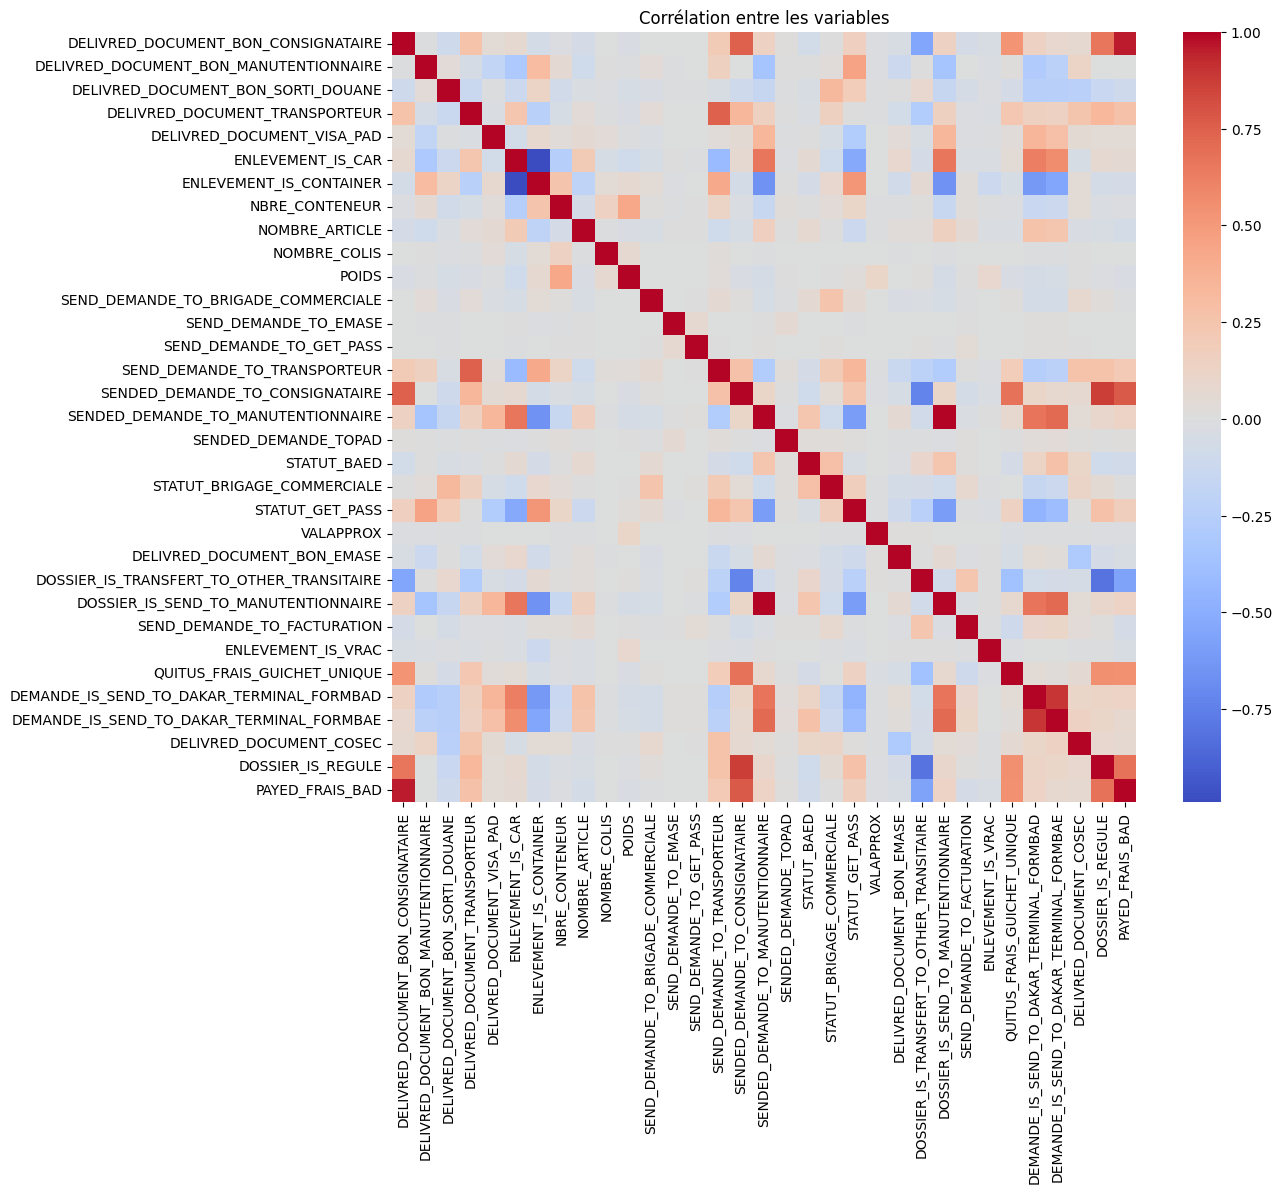

In [150]:
# matrice de correlation
corr = df_num.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=False, cmap="coolwarm")
plt.title("Corrélation entre les variables")
plt.show()

### Distribution des variables selon le cible

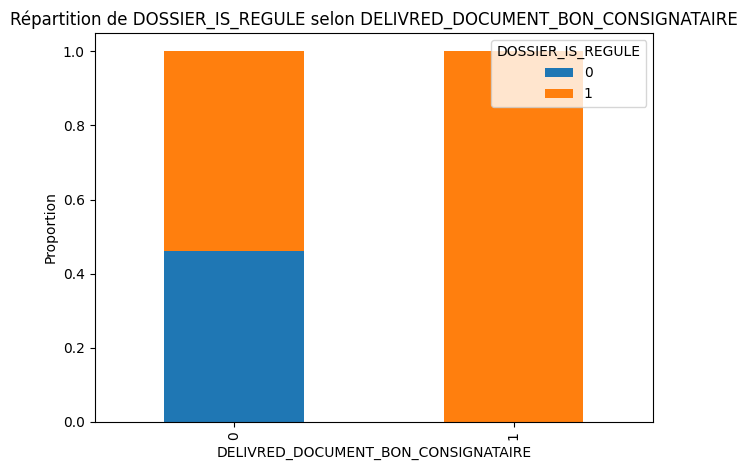

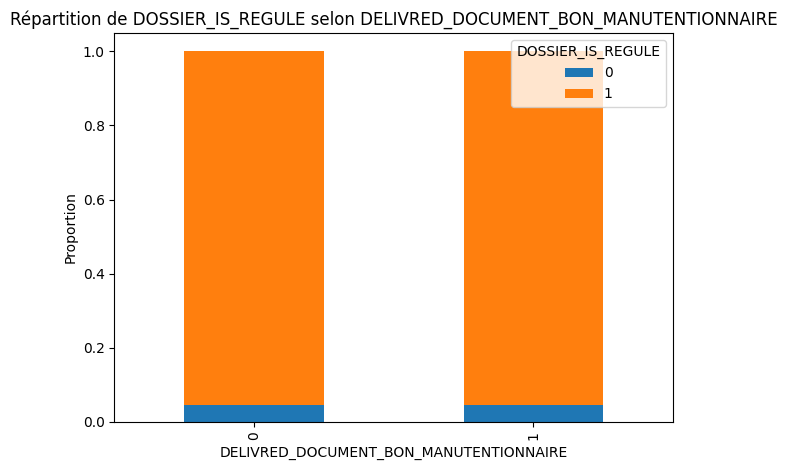

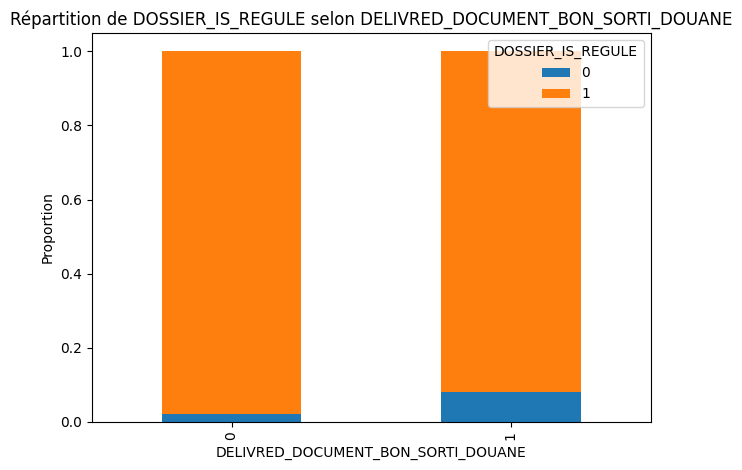

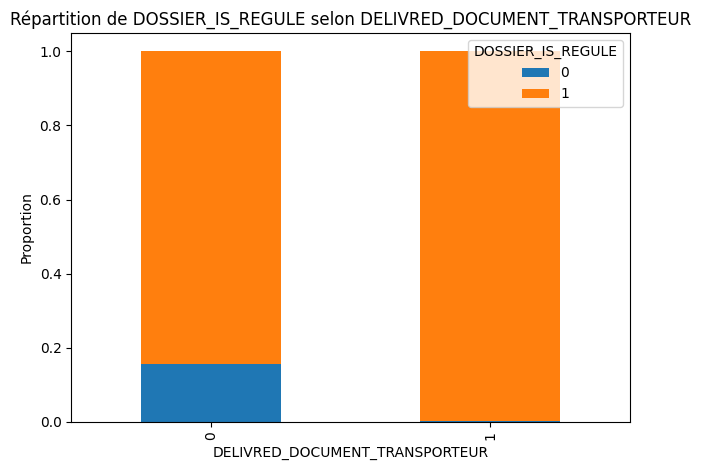

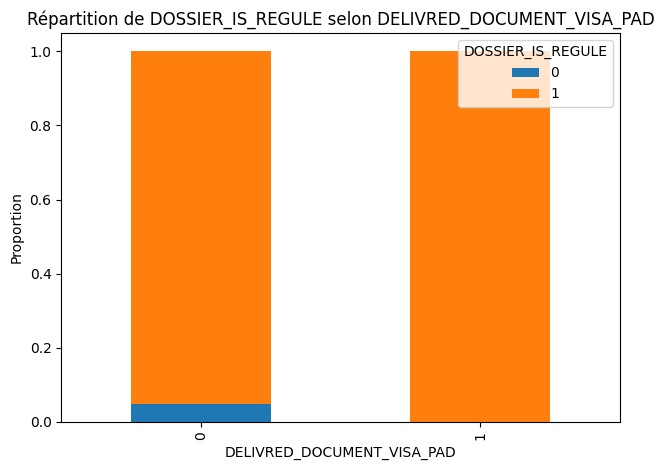

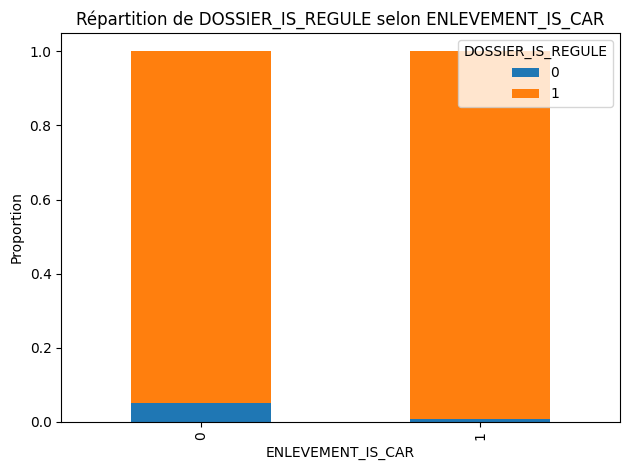

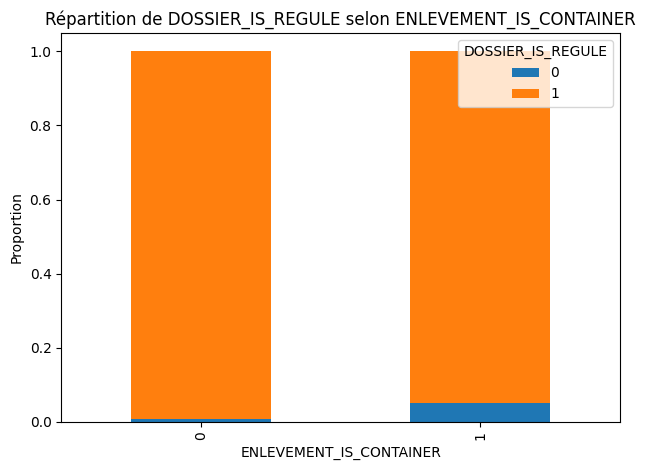

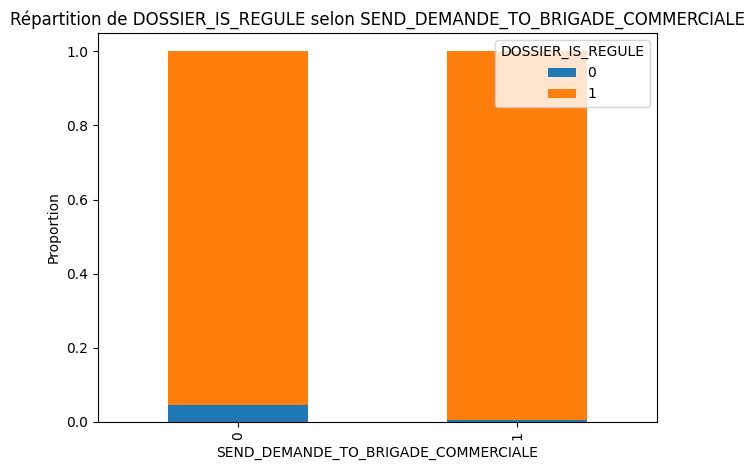

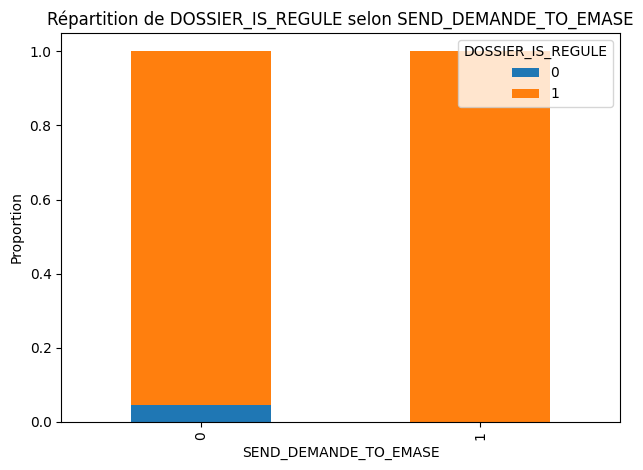

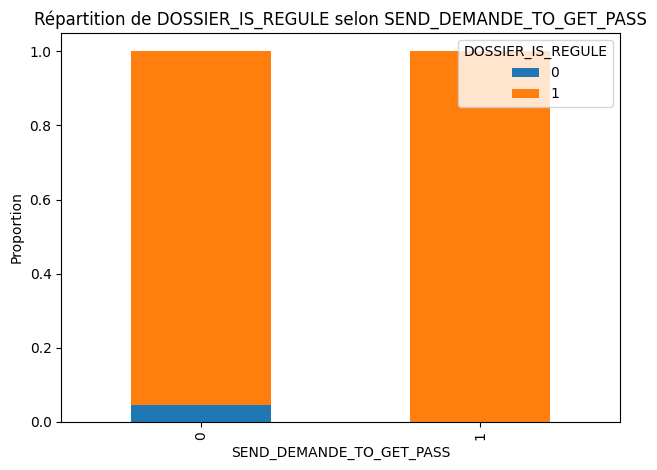

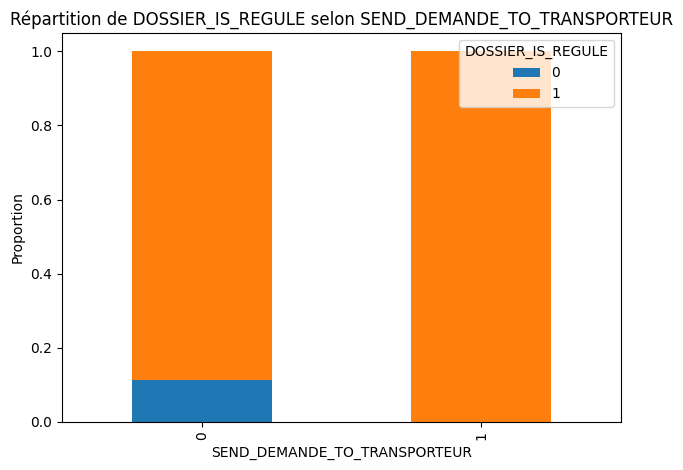

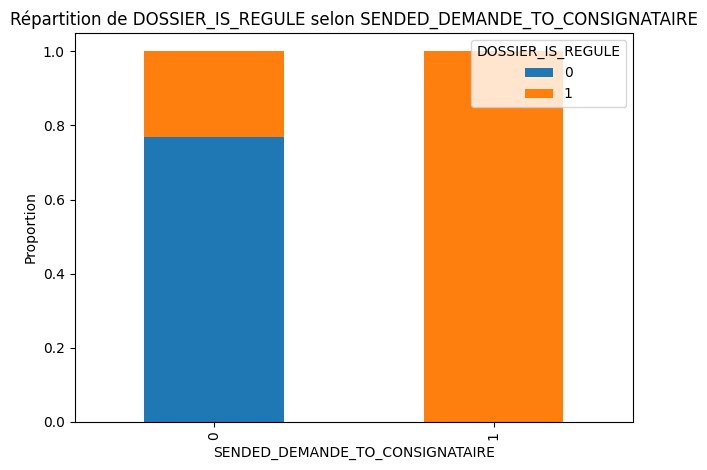

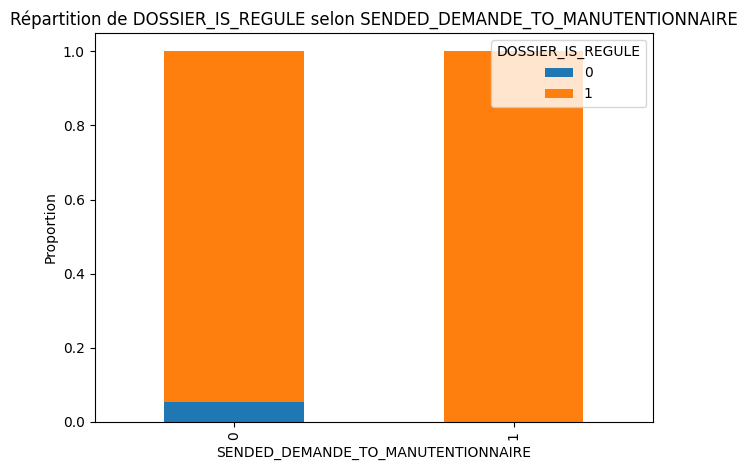

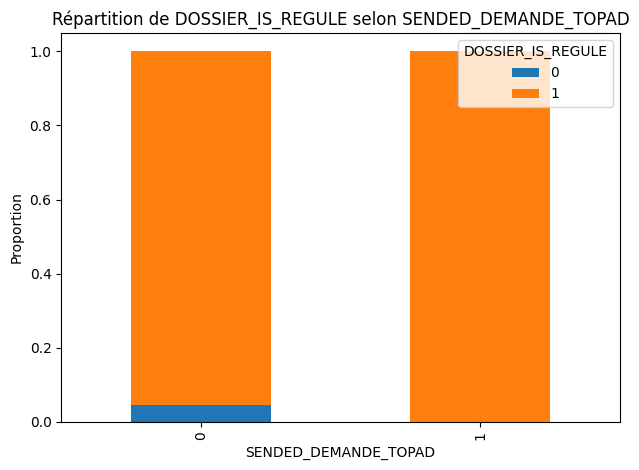

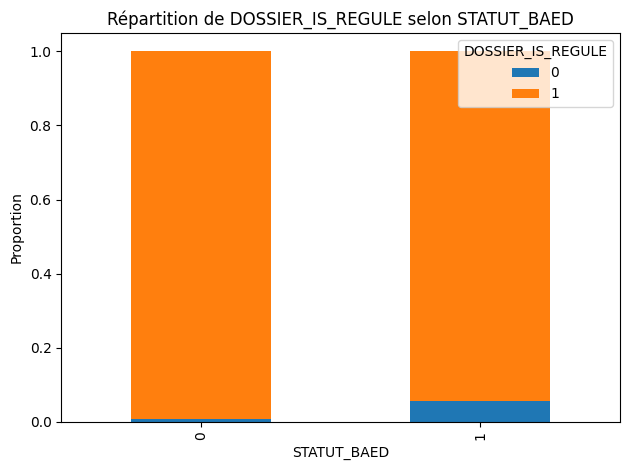

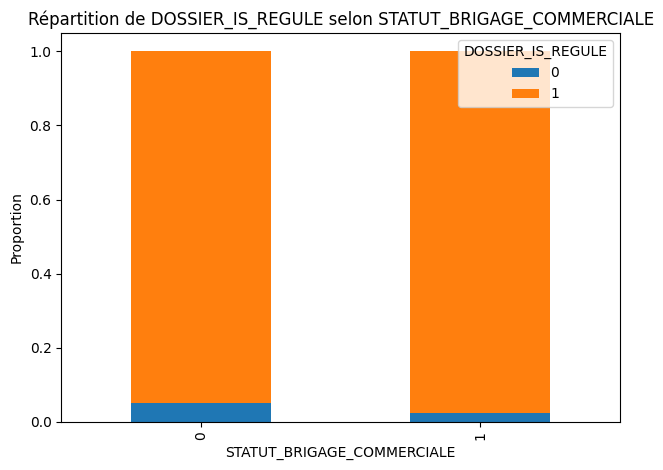

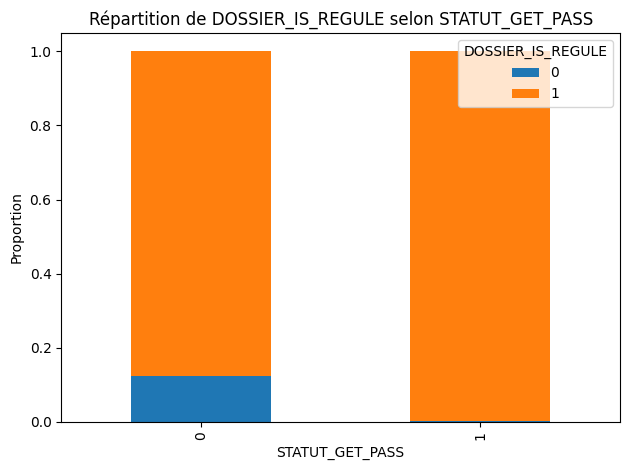

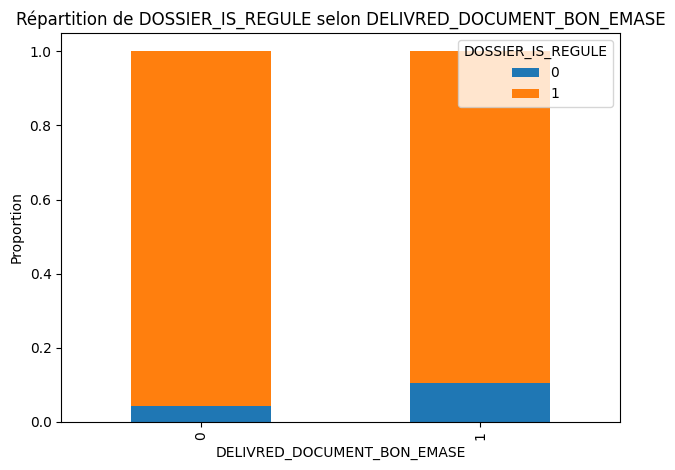

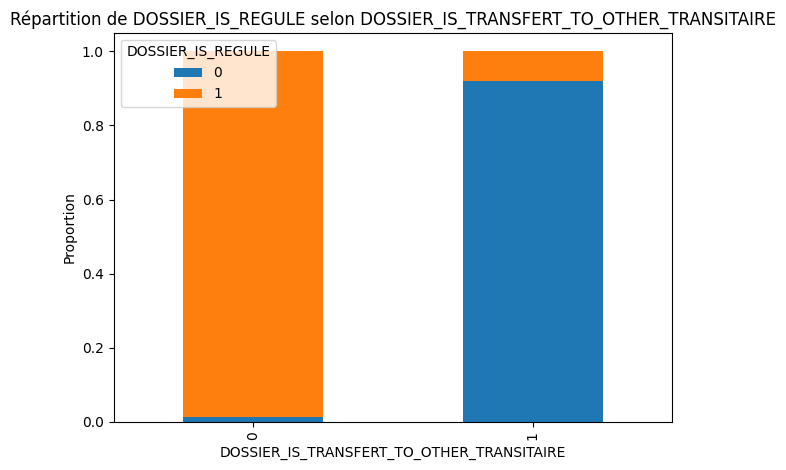

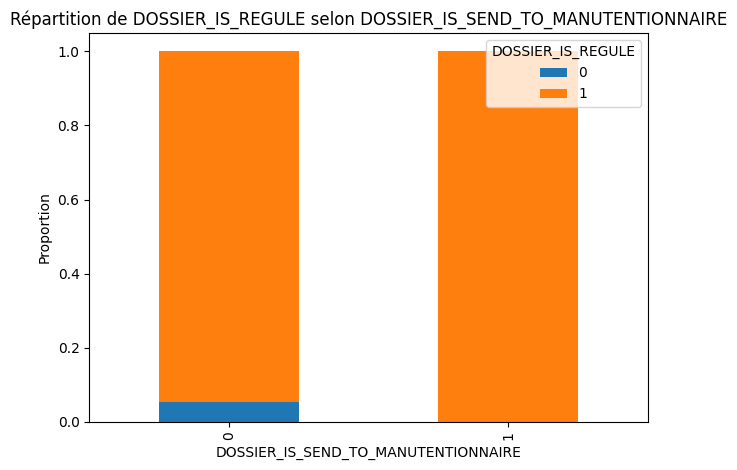

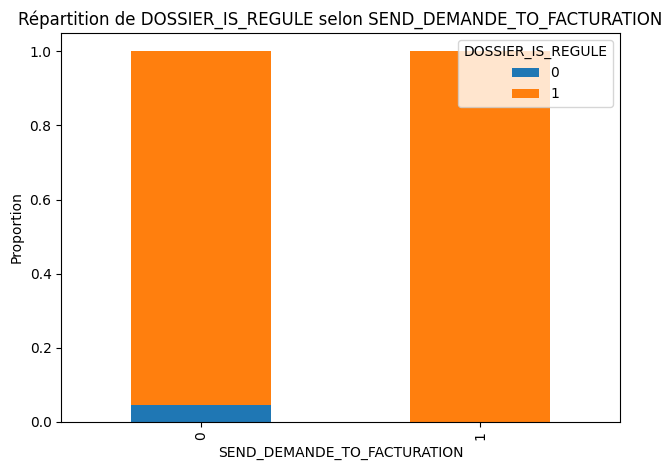

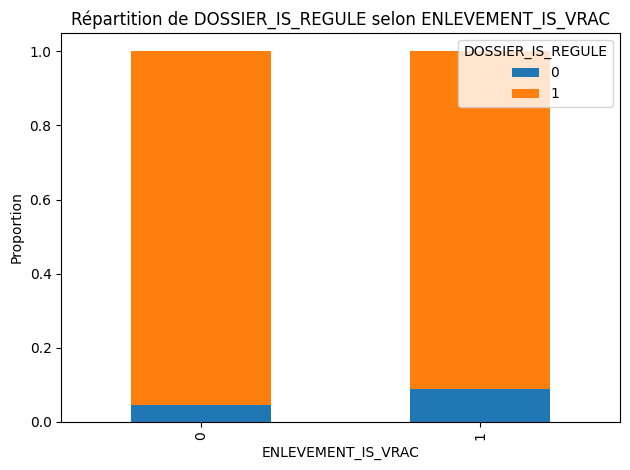

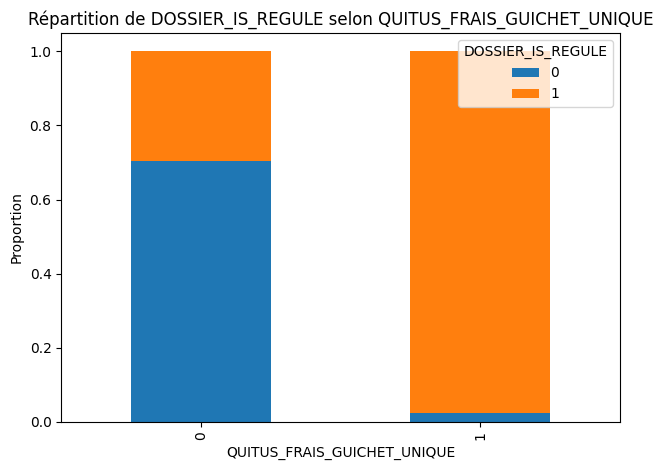

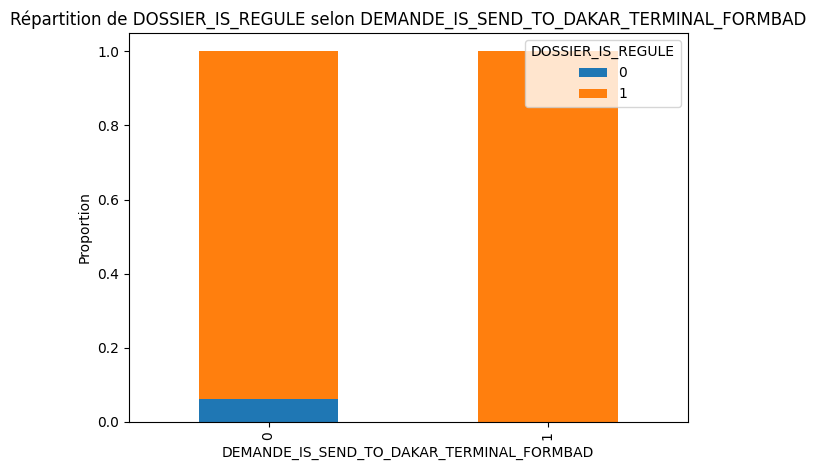

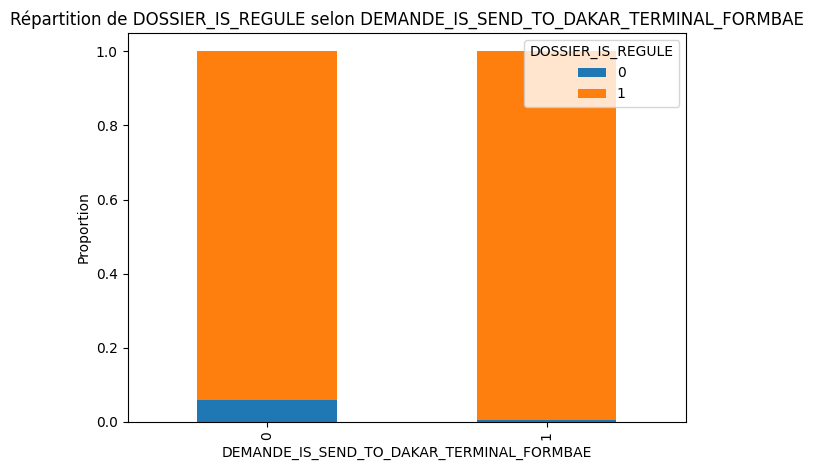

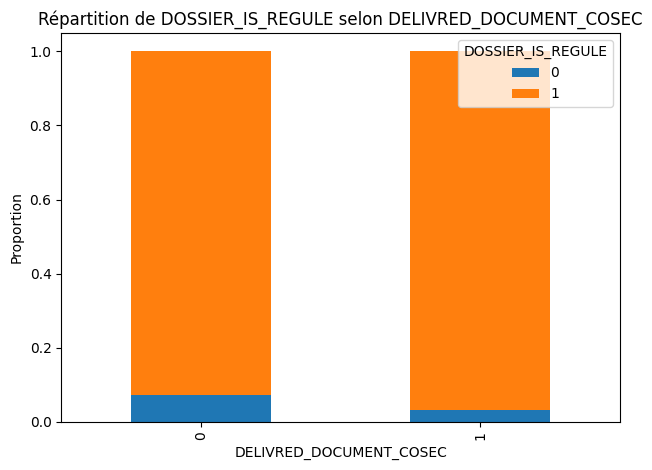

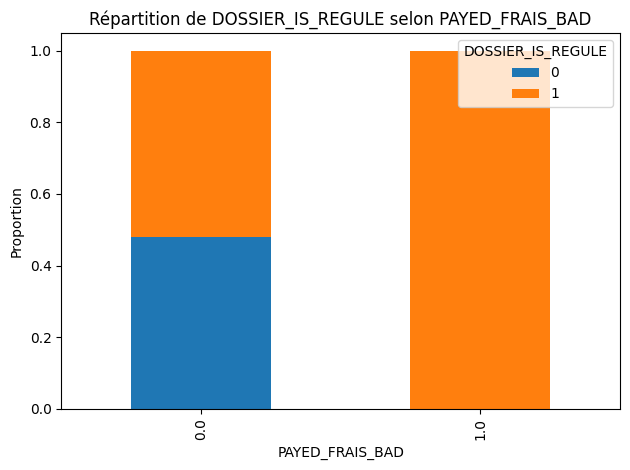

In [151]:
# visualisation de la repartition de la regularisation d'un dossier selon les varibles independantes
for col in df_num.columns:
    # Vérifie si la colonne est binaire (uniquement 0 et 1)
    if set(df_num[col].dropna().unique()).issubset({0, 1}) and col != 'DOSSIER_IS_REGULE':
        prop = pd.crosstab(df_num[col], df_num['DOSSIER_IS_REGULE'], normalize='index')
        prop.plot(kind='bar', stacked=True, title=f"Répartition de DOSSIER_IS_REGULE selon {col}")
        plt.xlabel(col)
        plt.ylabel("Proportion")
        plt.legend(title='DOSSIER_IS_REGULE')
        plt.tight_layout()
        plt.show()

### Proportion de dossier regule selon les variables

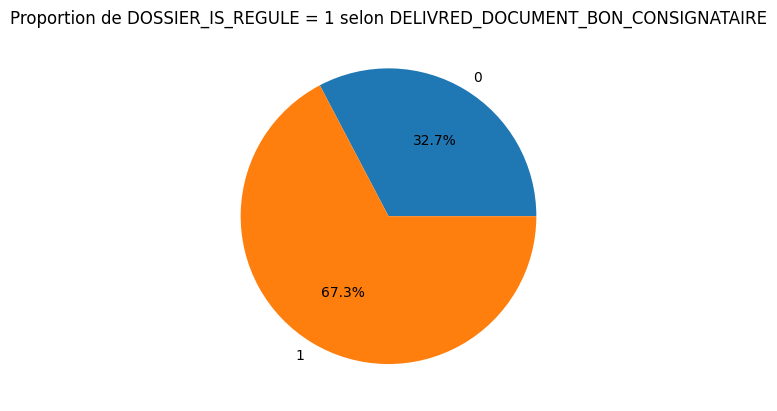

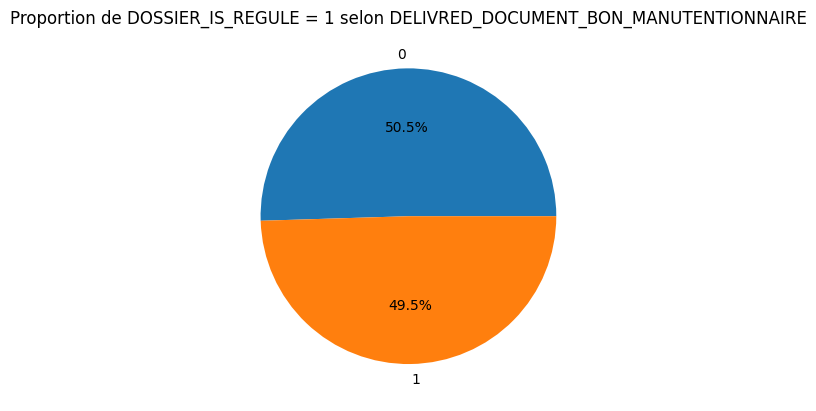

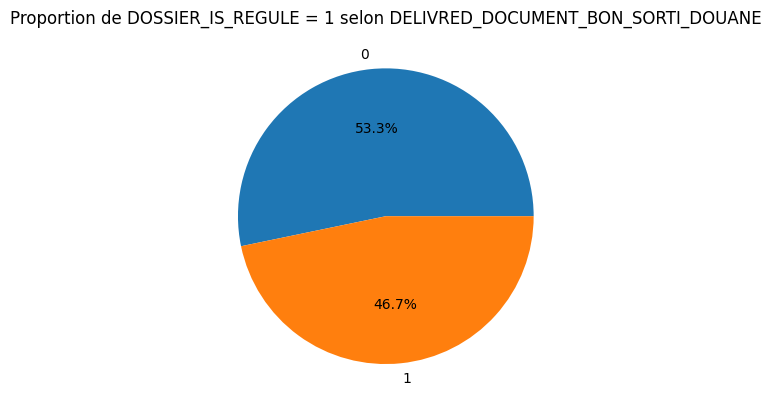

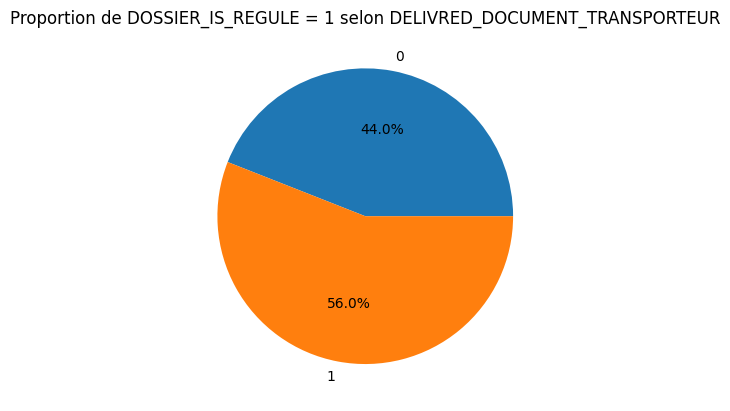

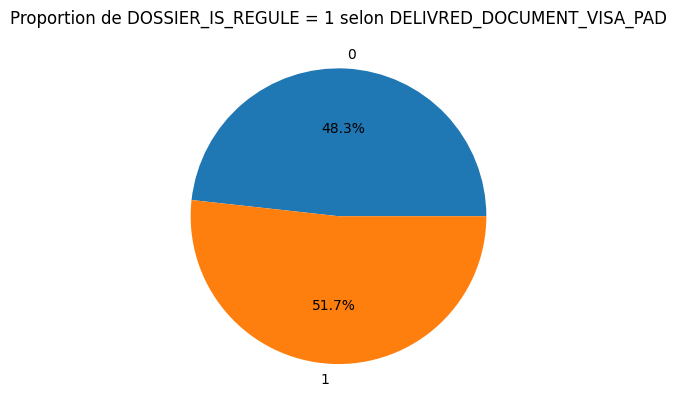

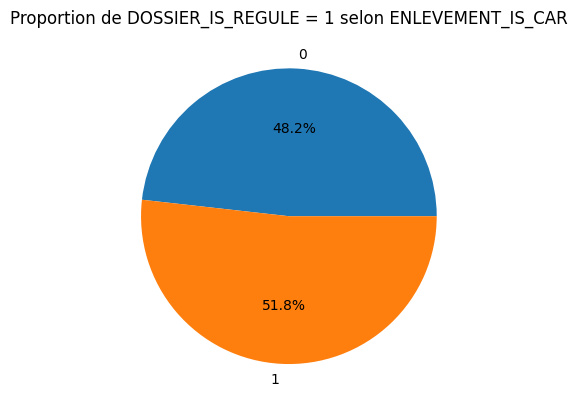

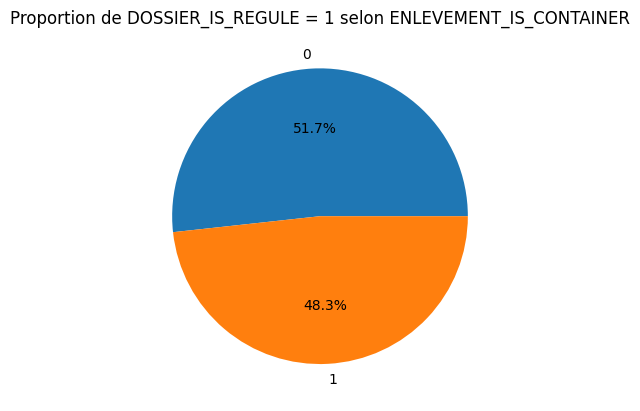

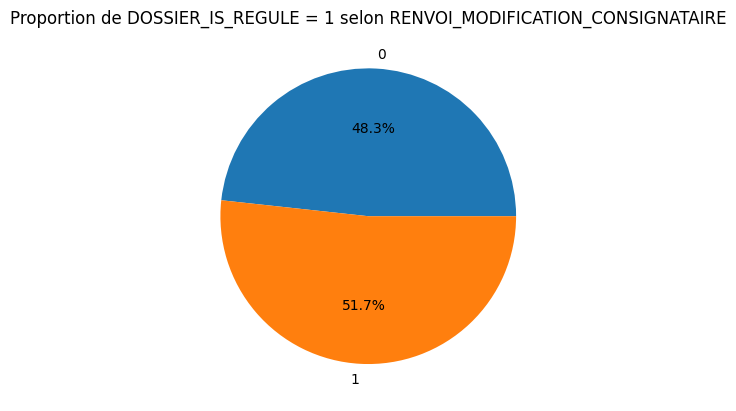

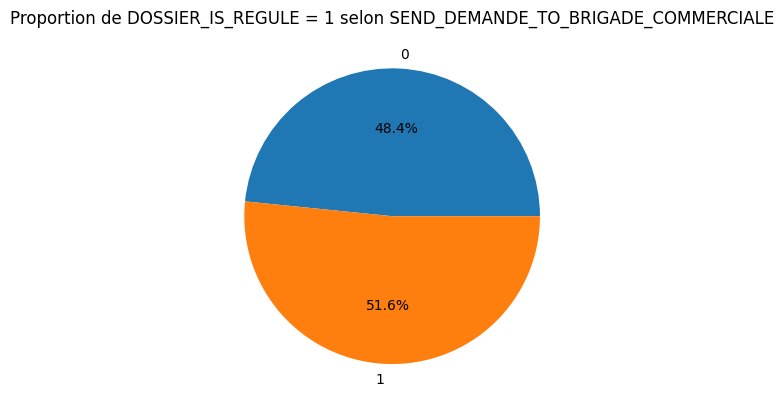

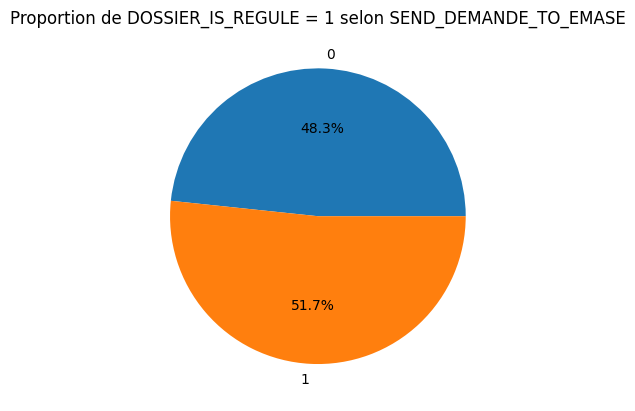

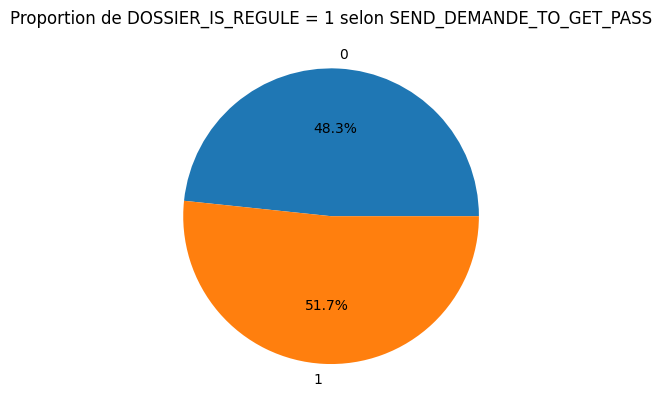

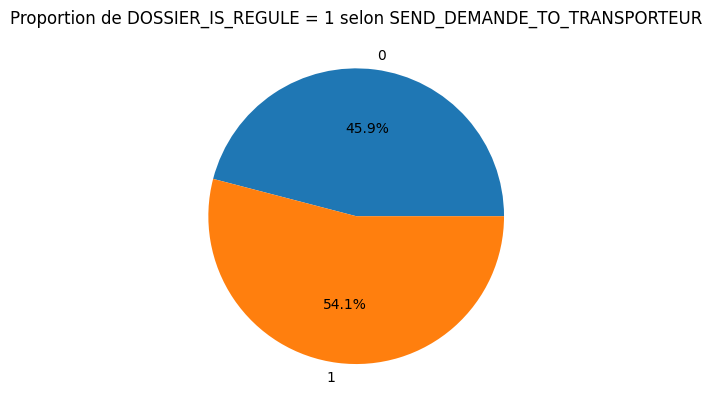

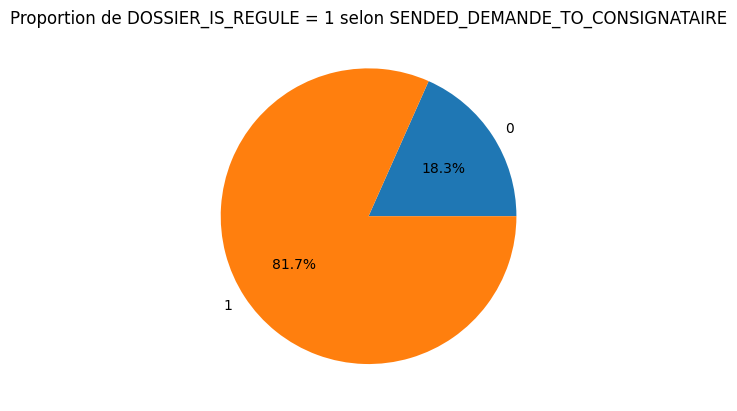

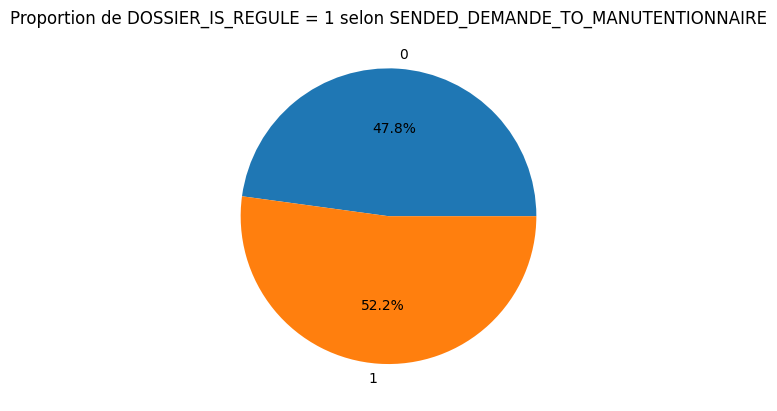

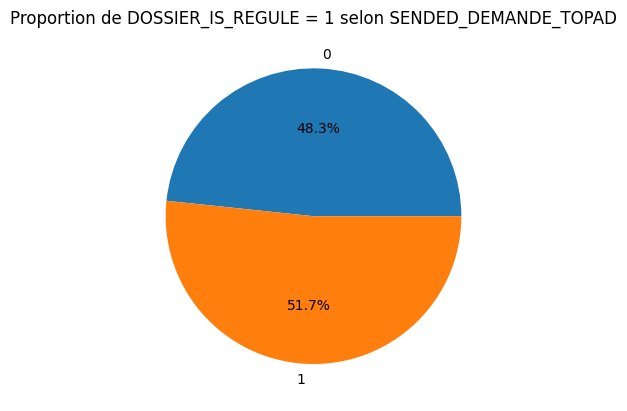

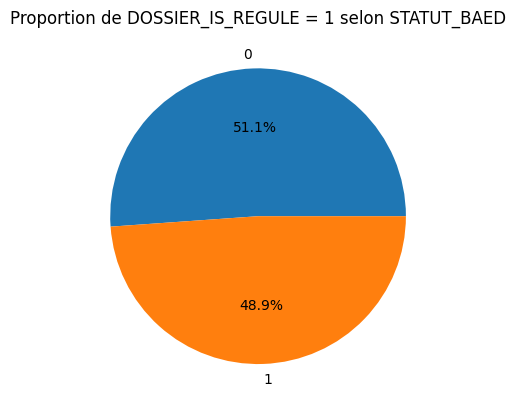

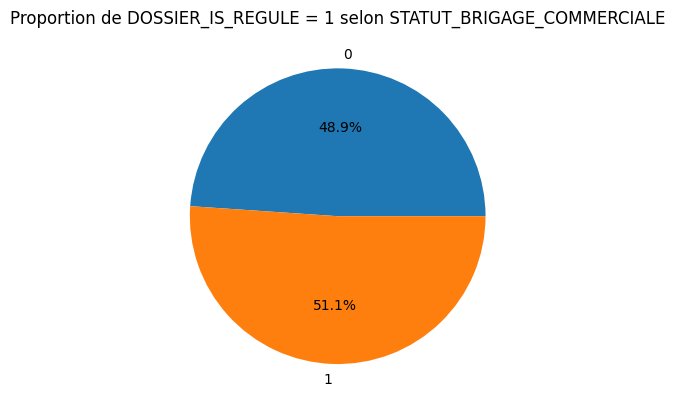

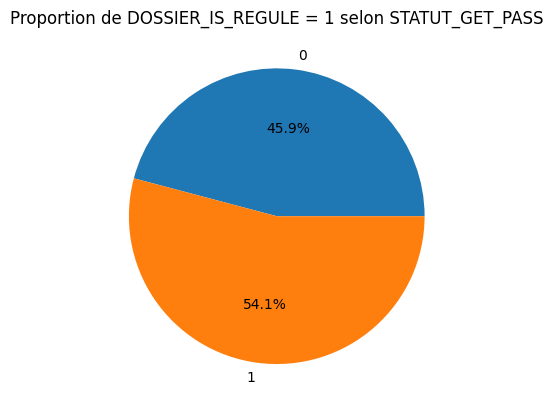

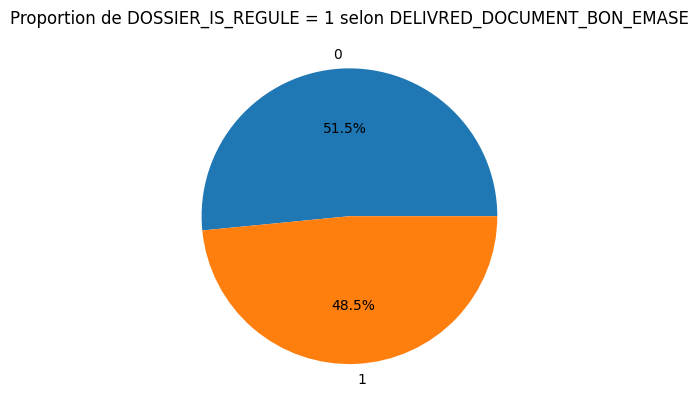

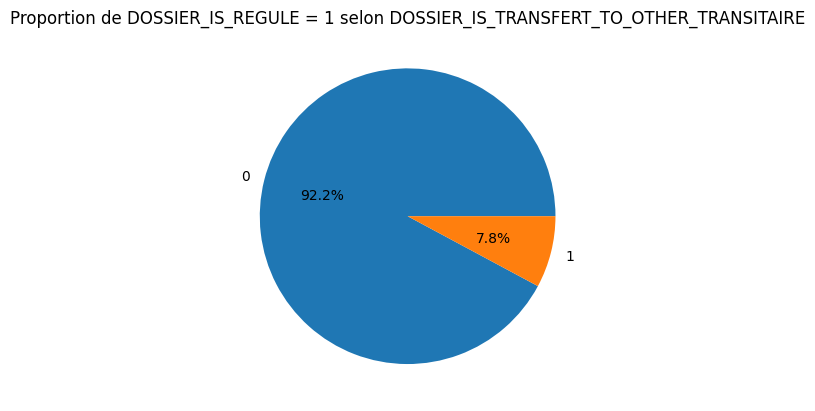

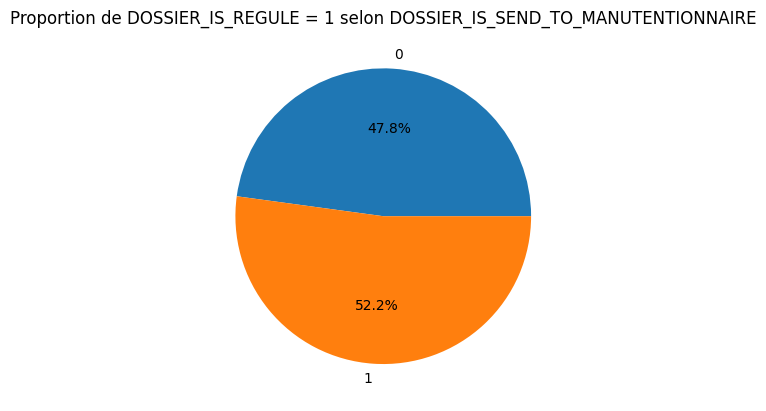

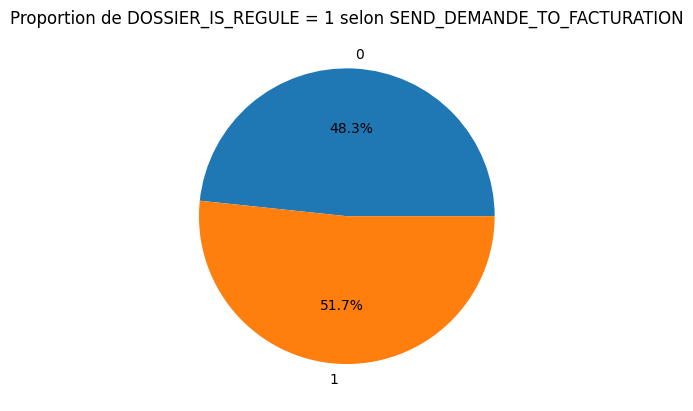

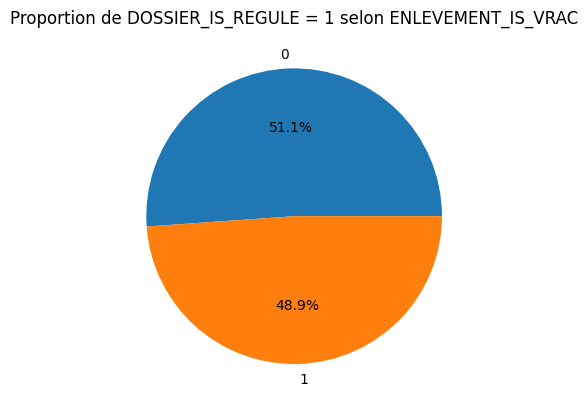

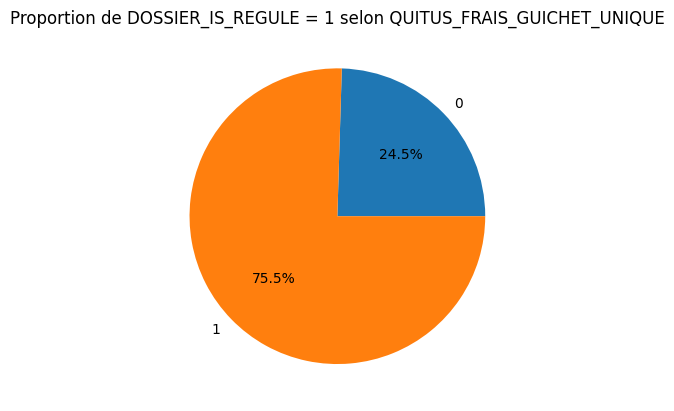

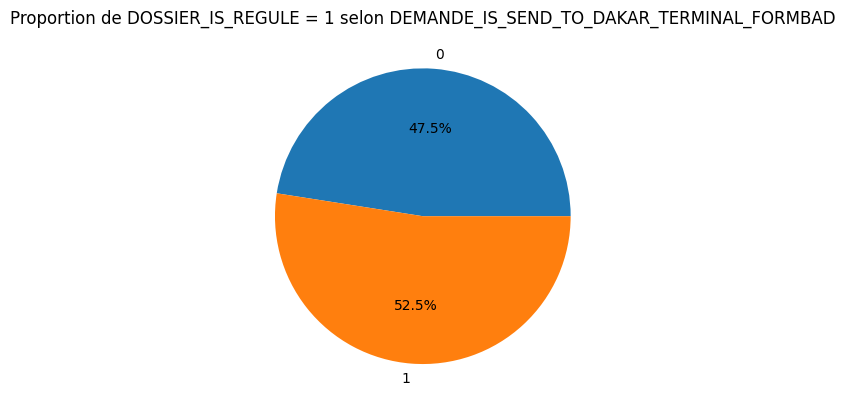

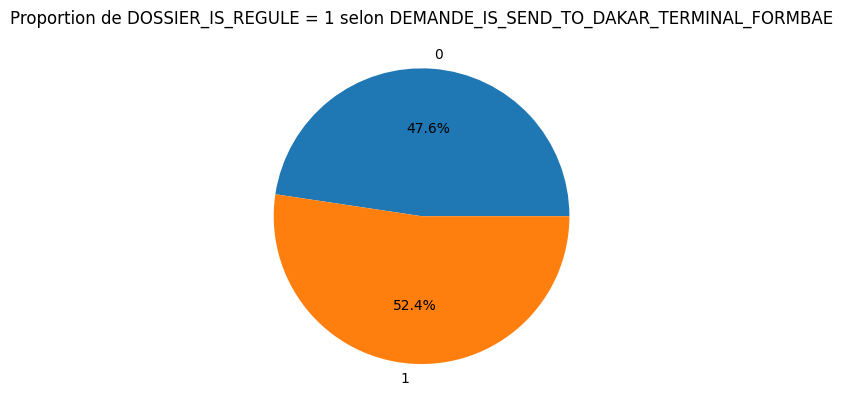

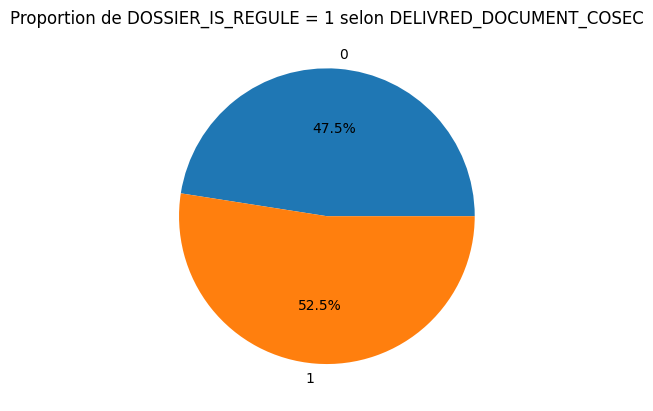

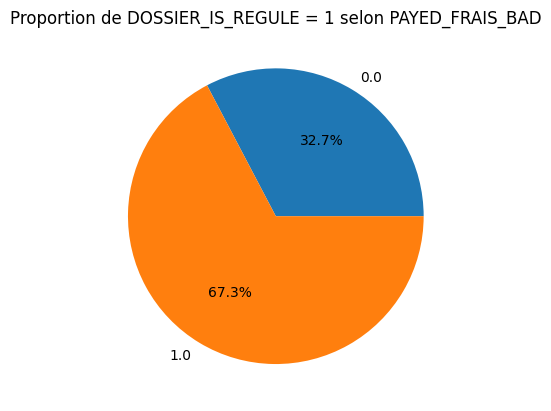

In [121]:
# visualisation de la repartition de la regularisation moyenne des dossiers selon les varibles independantes
for col in df_num.columns:
    if set(df_num[col].dropna().unique()).issubset({0, 1}) and col != 'DOSSIER_IS_REGULE':
        grouped = df_num.groupby(col)['DOSSIER_IS_REGULE'].mean()
        plt.pie(grouped.values, labels=grouped.index.astype(str), autopct='%.1f%%')
        plt.title(f"Proportion de DOSSIER_IS_REGULE = 1 selon {col}")
        plt.show()

## Variables categoriques

In [152]:
# extraction des variables categoriques
df_categoriques = df.select_dtypes(include='object')
df_categoriques.head()

,AUTRE_INFORMATION,BUREAU_DECLARATION,BUREAU_MANIF,CODE_AGENT,CODE_CONSIGNATAIRE,CODE_MANUTENTIONNAIRE,CODE_OPERATION,CODE_PAYS_DESTINATION,CODE_TRANSPORTEUR,CONSIGNATAIRE,DATE_ARRIVEE,DATE_DECLARATION,DATE_EMBARQUEMENT,DECLARANT,EMAIL_BENEFICIAIRE,LIBELLE_PAYS_DESTINATION,LIEU_EMBARQUEMENT,MANUTENTIONNAIRE,MODE_CONDITIONNEMENT,NAVIRE,NINEA_DECLARANT,NUMERO_MANIF,NUMERO_REPERTOIRE,ORDRE,PAVILLON,PAYS_DESTINATION,PPM_DECLARANT,PPM_DEMANDEUR,PPM_TRANSITAIRE,PROVENANCE,REGIME_DOUANIER,REGIME_FISCALE,RENVOI_MODIFICATION_CONSIGNATAIRE,STATUS,STATUSASP,STATUSBADC,STATUSBADM,STATUSBADT,STATUSPAD,TRANSPORTEUR,TYPEBL,TYPE_ENELEVEMENT,VILLE_DESTINATION,ZONE_LIVRAISON,ART,MOTIFDOUANE,DESCRIPTION,CODE_DOSSIER
0,None,None,10S,None,2,MT006,IMPORT001,0005SN,undefined,AFRICA GLOBAL LOGISTICS SENEGAL SA,2024-10-27 00:00:00,None,2024-10-20 00:00:00,None,steexpress@live.fr,SÉNÉGAL,VALENCE,DP World,CARTON,PEPI STAR,None,5600,AG2160,None,LIBÉRIA,SÉNÉGAL,531174,531174,531174,ESPAGNE,None,None,false,En cours,Initialisée,Délivré,Délivré,Délivré,Initialisée,Facture de transport,B/L Orignal,Conteneur,DAKAR,Dakar,72,None,None,D_NORM
1,None,15T,10S,None,2,MT006,TRANSIT001,0001ML,undefined,AFRICA GLOBAL LOGISTICS SENEGAL SA,2024-10-27 00:00:00,2024-10-25 00:00:00,2024-10-20 00:00:00,"TRANSIT KEUR AYIB - SUARL 90-94, RUE ABDOU KARIM BOURGI IMMEUBLE SERIGNE IB DAKAR",lamaniang96@gmail.com,MALI,VALENCE,DP World,COLIS (PARCEL),PEPI STAR,7261944,5600,AG2160,None,LIBÉRIA,MALI,141009,141009,141009,ESPAGNE,S1,10,false,En cours,Initialisée,Délivré,Délivré,Délivré,Initialisée,Facture de transport,B/L Orignal,Conteneur,BAMAKO,MOUSSALA,84,None,None,D_NORM
2,None,18N,18N,None,5265,MT006,IMPORT001,0005SN,undefined,DIAMOND SHIPPING,2024-08-12 00:00:00,2024-08-13 00:00:00,2024-08-12 00:00:00,"INTERNATIONAL SARL VTRANS RUE DAKAR,44 RUE TOLBIAC 3E ETAGE DAKAR",baylaythiombane1@gmail.com,SÉNÉGAL,YARIMCA,DP World,COLIS (PACKAGE),ULANGA,4099744,5277,102-HL,None,PORTUGAL,SÉNÉGAL,85963,85963,85963,MAROC,C1,0,false,En cours,Initialisée,Délivré,Délivré,Délivré,Initialisée,Facture de transport,B/L Orignal,Conteneur,SNDKR,DAKAR,314,None,"MATERIAUX DE POSTE,\rPREFABRIQUE SANS BETON",D_NORM
3,None,18N,18N,None,5265,MT006,IMPORT001,0005SN,undefined,DIAMOND SHIPPING,2024-09-02 00:00:00,2024-09-05 00:00:00,2024-08-30 00:00:00,SEN SOCIETE DE TRANSIT ET LOGISTIQUE - SUARL GARAGE SEBIKOTANE / DAKAR,None,SÉNÉGAL,MERSIN,DP World,BOITE (BOX),ALGECIRAS EXPRESS,8104531,5303,105-HL,None,LIBÉRIA,SÉNÉGAL,159473,159473,159473,MAROC,C1,0,false,En cours,Initialisée,Délivré,Délivré,Délivré,Initialisée,Facture de transport,B/L Orignal,Conteneur,SNDKR,DAKAR,148,None,CHOCOLATE FILLED COOKIES.,D_NORM
4,None,10S,10S,None,5265,MT006,IMPORT001,0005SN,undefined,DIAMOND SHIPPING,2024-04-25 00:00:00,2024-04-29 00:00:00,2024-04-29 00:00:00,ETS MBAYE TRANSPOR T TRANSIT BLD DJILY MBAYE IMM. RHV DAKAR,ndoyeabdou012@gmail.com,SENEGAL,MARPORT,DP World,COLIS (PACKAGE),IONIKOS,2833730,5247,087-HL,None,LIBÉRIA,SÉNÉGAL,30148,30148,30148,ESPAGNE,C1,0,false,En cours,Initialisée,Délivré,Délivré,Délivré,Initialisée,Facture de transport,B/L Orignal,Conteneur,SNDKR,ZONE 1,389,None,None,D_NORM


In [153]:
# analyse des variables categoriques
for col in df_categoriques.columns:
    print(f"--- {col} ---")
    print("Nombres de categories", len(df_categoriques[col].value_counts()), '\n')

--- AUTRE_INFORMATION ---
Nombres de categories 2083 

--- BUREAU_DECLARATION ---
Nombres de categories 8 

--- BUREAU_MANIF ---
Nombres de categories 4 

--- CODE_AGENT ---
Nombres de categories 14 

--- CODE_CONSIGNATAIRE ---
Nombres de categories 22 

--- CODE_MANUTENTIONNAIRE ---
Nombres de categories 5 

--- CODE_OPERATION ---
Nombres de categories 2 

--- CODE_PAYS_DESTINATION ---
Nombres de categories 7 

--- CODE_TRANSPORTEUR ---
Nombres de categories 60 

--- CONSIGNATAIRE ---
Nombres de categories 35 

--- DATE_ARRIVEE ---
Nombres de categories 485 

--- DATE_DECLARATION ---
Nombres de categories 493 

--- DATE_EMBARQUEMENT ---
Nombres de categories 570 

--- DECLARANT ---
Nombres de categories 424 

--- EMAIL_BENEFICIAIRE ---
Nombres de categories 2425 

--- LIBELLE_PAYS_DESTINATION ---
Nombres de categories 8 

--- LIEU_EMBARQUEMENT ---
Nombres de categories 607 

--- MANUTENTIONNAIRE ---
Nombres de categories 8 

--- MODE_CONDITIONNEMENT ---
Nombres de categories 134 

---

### Encodage des variables categoriques

In [124]:
def categorize(df):
    """
    Encode toutes les colonnes catégoriques (object/category) avec un mapping numérique.
    Retourne : dictionnaire des mappings + copie du DataFrame transformé
    """
    df_copy = df.copy()
    mappings = {}

    # On ne traite que les colonnes catégoriques
    cat_cols = df_copy.select_dtypes(include=["object", "category"]).columns

    for col in cat_cols:
        unique_vals = df_copy[col].dropna().unique()
        mapping = {val: idx for idx, val in enumerate(unique_vals)}
        df_copy[col] = df_copy[col].map(mapping)
        mappings[col] = mapping

    return mappings, df_copy


In [125]:
mapping, df_encoded = categorize(df_categoriques)
df_encoded.head(10)

,AUTRE_INFORMATION,BUREAU_DECLARATION,BUREAU_MANIF,CODE_AGENT,CODE_CONSIGNATAIRE,CODE_MANUTENTIONNAIRE,CODE_OPERATION,CODE_PAYS_DESTINATION,CODE_TRANSPORTEUR,CONSIGNATAIRE,DATE_ARRIVEE,DATE_CREATION,DATE_DECLARATION,DATE_EMBARQUEMENT,DATE_TRAITEMENT_DEFINITIVE,DECLARANT,EMAIL_BENEFICIAIRE,LIBELLE_PAYS_DESTINATION,LIEU_EMBARQUEMENT,MANUTENTIONNAIRE,MODE_CONDITIONNEMENT,NAVIRE,NINEA_DECLARANT,NUMERO_REPERTOIRE,ORDRE,PAVILLON,PAYS_DESTINATION,PPM_DEMANDEUR,PPM_TRANSITAIRE,PROVENANCE,REGIME_DOUANIER,STATUS,STATUSASP,STATUSBADC,STATUSBADM,STATUSBADT,STATUSPAD,TRANSPORTEUR,TYPEBL,TYPE_ENELEVEMENT,VILLE_DESTINATION,ZONE_LIVRAISON,LOCAL_DATEBAD,MOTIFDOUANE,DESCRIPTION,CODE_DOSSIER
0,NaN,0.0,0,NaN,0,0.0,0,0,NaN,0.0,0,0,0.0,0,NaN,0.0,0.0,0,0,0,0.0,0,0.0,0,NaN,0,0,0.0,0.0,0,0.0,0,0,0,0,NaN,0,NaN,0,0,0.0,0.0,0.0,NaN,NaN,0.0
1,NaN,NaN,1,NaN,1,0.0,0,0,NaN,1.0,1,1,NaN,1,NaN,NaN,1.0,1,1,0,1.0,1,NaN,1,NaN,1,0,1.0,1.0,1,NaN,0,0,0,0,NaN,0,NaN,1,0,0.0,1.0,NaN,NaN,NaN,0.0
2,NaN,1.0,1,NaN,2,1.0,0,0,0.0,2.0,2,2,1.0,2,0.0,1.0,NaN,0,2,1,2.0,2,1.0,2,NaN,2,0,2.0,2.0,2,0.0,1,1,0,1,0.0,0,0.0,2,1,0.0,2.0,1.0,NaN,NaN,0.0
3,NaN,1.0,1,NaN,2,1.0,0,0,NaN,2.0,3,3,2.0,3,NaN,2.0,2.0,0,2,1,3.0,3,2.0,3,NaN,3,0,3.0,3.0,3,0.0,0,0,0,1,NaN,0,NaN,2,1,0.0,3.0,2.0,NaN,NaN,0.0
4,NaN,2.0,0,NaN,3,0.0,1,1,NaN,3.0,4,4,3.0,4,NaN,3.0,3.0,2,1,0,2.0,4,3.0,4,NaN,2,1,4.0,4.0,4,1.0,0,0,0,0,NaN,0,NaN,2,0,1.0,4.0,3.0,NaN,NaN,0.0
5,NaN,2.0,1,NaN,3,0.0,1,1,NaN,3.0,5,5,4.0,5,NaN,3.0,4.0,2,1,0,2.0,5,3.0,5,NaN,4,1,4.0,4.0,5,1.0,0,0,0,0,NaN,0,NaN,1,0,1.0,5.0,4.0,NaN,NaN,0.0
6,0.0,2.0,2,NaN,4,1.0,1,1,NaN,4.0,6,6,5.0,6,NaN,4.0,5.0,2,3,1,4.0,6,4.0,6,NaN,5,1,5.0,5.0,2,1.0,0,0,0,1,NaN,0,NaN,1,1,2.0,5.0,5.0,NaN,NaN,0.0
7,NaN,2.0,0,NaN,5,1.0,1,1,NaN,5.0,7,7,6.0,7,NaN,4.0,6.0,2,4,1,4.0,7,4.0,7,NaN,5,1,5.0,5.0,6,1.0,0,0,0,1,NaN,0,NaN,1,1,3.0,5.0,6.0,NaN,NaN,0.0
8,1.0,NaN,1,NaN,0,0.0,0,0,NaN,0.0,8,2,NaN,8,NaN,NaN,7.0,0,1,0,0.0,8,NaN,8,NaN,2,0,6.0,6.0,7,NaN,0,0,0,0,NaN,0,NaN,1,0,0.0,0.0,7.0,NaN,NaN,0.0
9,2.0,3.0,2,NaN,4,1.0,0,0,0.0,4.0,9,8,7.0,9,NaN,5.0,8.0,1,5,1,5.0,9,5.0,9,NaN,3,0,7.0,7.0,2,0.0,0,0,0,1,0.0,0,0.0,1,1,4.0,2.0,8.0,NaN,NaN,0.0


In [155]:
# liste des colonnes
columns = list(df_num.columns)
columns

['DELIVRED_DOCUMENT_BON_CONSIGNATAIRE',
 'DELIVRED_DOCUMENT_BON_MANUTENTIONNAIRE',
 'DELIVRED_DOCUMENT_BON_SORTI_DOUANE',
 'DELIVRED_DOCUMENT_TRANSPORTEUR',
 'DELIVRED_DOCUMENT_VISA_PAD',
 'ENLEVEMENT_IS_CAR',
 'ENLEVEMENT_IS_CONTAINER',
 'NBRE_CONTENEUR',
 'NOMBRE_ARTICLE',
 'NOMBRE_COLIS',
 'POIDS',
 'SEND_DEMANDE_TO_BRIGADE_COMMERCIALE',
 'SEND_DEMANDE_TO_EMASE',
 'SEND_DEMANDE_TO_GET_PASS',
 'SEND_DEMANDE_TO_TRANSPORTEUR',
 'SENDED_DEMANDE_TO_CONSIGNATAIRE',
 'SENDED_DEMANDE_TO_MANUTENTIONNAIRE',
 'SENDED_DEMANDE_TOPAD',
 'STATUT_BAED',
 'STATUT_BRIGAGE_COMMERCIALE',
 'STATUT_GET_PASS',
 'VALAPPROX',
 'DELIVRED_DOCUMENT_BON_EMASE',
 'DOSSIER_IS_TRANSFERT_TO_OTHER_TRANSITAIRE',
 'DOSSIER_IS_SEND_TO_MANUTENTIONNAIRE',
 'SEND_DEMANDE_TO_FACTURATION',
 'ENLEVEMENT_IS_VRAC',
 'QUITUS_FRAIS_GUICHET_UNIQUE',
 'DEMANDE_IS_SEND_TO_DAKAR_TERMINAL_FORMBAD',
 'DEMANDE_IS_SEND_TO_DAKAR_TERMINAL_FORMBAE',
 'DELIVRED_DOCUMENT_COSEC',
 'DOSSIER_IS_REGULE',
 'PAYED_FRAIS_BAD']

In [156]:
# df final
df_final = df_num[columns].dropna()
df_final.shape

(110239, 33)

# Modelisation et evaluation

In [158]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

# 1. Definir les variables explicatives X et la cible y

X = df_final[["SENDED_DEMANDE_TO_CONSIGNATAIRE",
    "PAYED_FRAIS_BAD",
    "DELIVRED_DOCUMENT_BON_CONSIGNATAIRE",
    "DOSSIER_IS_TRANSFERT_TO_OTHER_TRANSITAIRE",
    "STATUT_GET_PASS",
    "DELIVRED_DOCUMENT_TRANSPORTEUR",
    "SEND_DEMANDE_TO_TRANSPORTEUR",
    "DEMANDE_IS_SEND_TO_DAKAR_TERMINAL_FORMBAD",
    "QUITUS_FRAIS_GUICHET_UNIQUE",
    "DELIVRED_DOCUMENT_BON_SORTI_DOUANE",
    "SENDED_DEMANDE_TO_MANUTENTIONNAIRE",
    "DEMANDE_IS_SEND_TO_DAKAR_TERMINAL_FORMBAE",
    "NOMBRE_ARTICLE",
    "POIDS",
    "DOSSIER_IS_SEND_TO_MANUTENTIONNAIRE",
    "NOMBRE_COLIS"]]

'''X = df_final[["SENDED_DEMANDE_TO_CONSIGNATAIRE",



    "STATUT_GET_PASS",

    "SEND_DEMANDE_TO_TRANSPORTEUR",





    "NOMBRE_ARTICLE",
    "POIDS",

    "NOMBRE_COLIS"]]'''

y = df_final['DOSSIER_IS_REGULE'] # Cible binaire (0: bloque, 1: regularise)

# 2. Separer en train / test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 3. Modele Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",  # Important vu le desequilibre
    random_state=42
)
rf_model.fit(X_train, y_train)

# 4. Predictions
y_pred = rf_model.predict(X_test)

# 5. evaluation
print("=== Matrice de confusion ===")
print(confusion_matrix(y_test, y_pred))

print("\n=== Rapport de classification ===")
print(classification_report(y_test, y_pred, digits=3))

=== Matrice de confusion ===
[[  972    28]
 [   23 21025]]

=== Rapport de classification ===
              precision    recall  f1-score   support

           0      0.977     0.972     0.974      1000
           1      0.999     0.999     0.999     21048

    accuracy                          0.998     22048
   macro avg      0.988     0.985     0.987     22048
weighted avg      0.998     0.998     0.998     22048



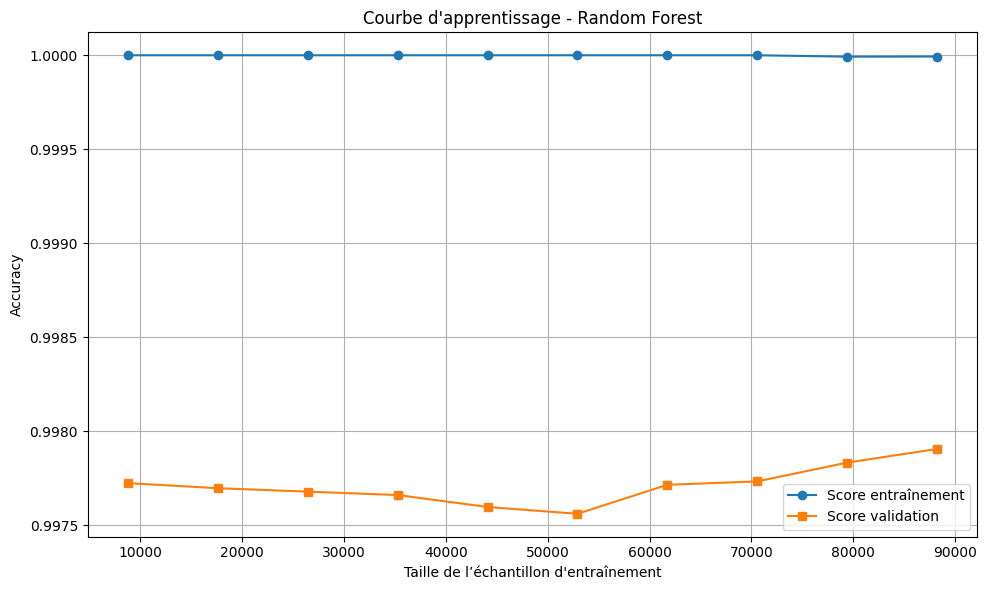

In [159]:
from sklearn.model_selection import learning_curve, StratifiedKFold

# Courbe d'apprentissage
train_sizes, train_scores, val_scores = learning_curve(
    estimator=rf_model,
    X=X,
    y=y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='accuracy',
    n_jobs=-1
)

# Moyennes
train_scores_mean = train_scores.mean(axis=1)
val_scores_mean = val_scores.mean(axis=1)

# Affichage
plt.figure(figsize=(10,6))
plt.plot(train_sizes, train_scores_mean, label='Score entraînement', marker='o')
plt.plot(train_sizes, val_scores_mean, label='Score validation', marker='s')
plt.title("Courbe d'apprentissage - Random Forest")
plt.xlabel("Taille de l’échantillon d'entraînement")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

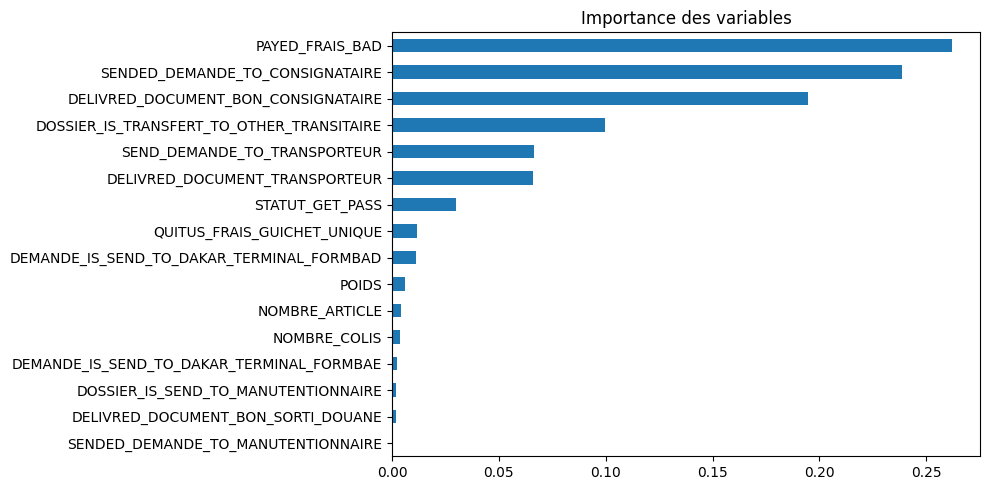

In [160]:
import matplotlib.pyplot as plt

# Importance des variables
importances = pd.Series(rf_model.feature_importances_, index=X.columns)
importances.sort_values(ascending=True).plot(kind='barh', figsize=(10, 5), title="Importance des variables")
plt.tight_layout()
plt.show()